# 01 — Exploratory Data Analysis

**Dataset:** *Give Me Some Credit* (150 000 borrowers, target — serious delinquency 90+ days within 2 years).
The pipeline also supports *Home Credit Default Risk* (`dataset: home_credit` in `configs/config.yaml`).

Goals of this notebook:
1. default rate (class balance);
2. missing values;
3. feature distributions and outliers / data-quality issues;
4. how the default rate depends on key features;
5. conclusions that drive feature engineering and model choice.

Run `make data` first. EDA is done on the full table only to *understand* the data —
no statistic computed here is used by the model (all learned transformations live in the sklearn pipeline).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 100

DATA = Path("..") / "data" / "processed"
df = pd.read_parquet(DATA / "dataset.parquet")
meta = json.loads((DATA / "meta.json").read_text())
print(meta)
df.head()

{'dataset': 'gmsc', 'n_rows': 150000, 'n_columns': 10, 'default_rate': 0.06684, 'id_column': None}


,revolving_utilization,age,past_due_30_59,debt_ratio,monthly_income,open_credit_lines,times_90_days_late,real_estate_loans,past_due_60_89,dependents,target
0,0.030,57,0,0.283,"10,121.000",7,0,1,0,0.000,0
1,0.000,57,0,0.143,"7,750.000",9,0,1,0,0.000,0
2,0.037,48,0,0.236,"6,000.000",6,0,2,0,3.000,0
3,1.018,41,0,0.163,"4,958.000",4,0,0,0,0.000,0
4,1.009,49,0,"3,942.000",NaN,10,0,1,0,0.000,0


## 1. Target: default rate

rows: 150,000 | defaults: 10,026 | default rate: 6.68%


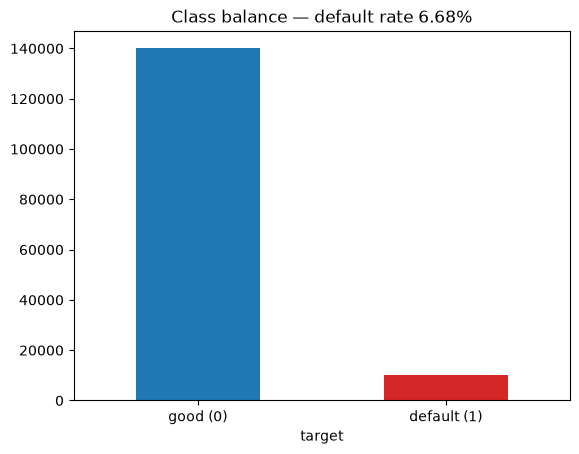

In [2]:
rate = df["target"].mean()
print(f"rows: {len(df):,} | defaults: {df['target'].sum():,} | default rate: {rate:.2%}")
ax = df["target"].value_counts().sort_index().plot.bar(color=["tab:blue", "tab:red"])
ax.set_xticklabels(["good (0)", "default (1)"], rotation=0)
ax.set_title(f"Class balance — default rate {rate:.2%}")
plt.show()

The classes are imbalanced (~6.7% defaults, ~1:14). Consequences:
* **accuracy is useless** (predicting "no default" for everyone gives 93%) → use ROC-AUC / Gini, PR-AUC, KS;
* stratified splits and Stratified K-Fold keep the same default rate in every fold;
* we do **not** oversample / reweight: the bank needs a calibrated probability of default (PD),
  and the decision threshold is handled separately with a cost matrix.

## 2. Missing values

In [3]:
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
display(missing.to_frame("share_missing"))
for col in missing.index:
    print(f"default rate | {col} missing: {df.loc[df[col].isna(), 'target'].mean():.2%}"
          f"  vs present: {df.loc[df[col].notna(), 'target'].mean():.2%}")

,share_missing
monthly_income,0.198
dependents,0.026


default rate | monthly_income missing: 5.61%  vs present: 6.95%
default rate | dependents missing: 4.56%  vs present: 6.74%


* `monthly_income` is missing for ~20% of borrowers, `dependents` for ~2.6%.
* Missingness itself is informative: borrowers without reported income default *less* often
  (5.6% vs 7.0%), so a missing value is not "average income" → for linear models we add **missing-indicator**
  columns (`SimpleImputer(add_indicator=True)`) and an explicit `income_missing` flag; gradient boosting
  handles NaN natively and learns the best direction for missing values.
* Imputation medians are learned **inside the pipeline on the training fold only** — no leakage.

## 3. Distributions and data-quality issues

In [4]:
df.describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
revolving_utilization,"150,000.000",6.048,249.755,0.000,0.000,0.154,1.093,"50,708.000"
age,"150,000.000",52.295,14.772,0.000,24.000,52.000,87.000,109.000
past_due_30_59,"150,000.000",0.421,4.193,0.000,0.000,0.000,4.000,98.000
debt_ratio,"150,000.000",353.005,"2,037.819",0.000,0.000,0.367,"4,979.040","329,664.000"
monthly_income,"120,269.000","6,670.221","14,384.674",0.000,0.000,"5,400.000","25,000.000","3,008,750.000"
open_credit_lines,"150,000.000",8.453,5.146,0.000,0.000,8.000,24.000,58.000
times_90_days_late,"150,000.000",0.266,4.169,0.000,0.000,0.000,3.000,98.000
real_estate_loans,"150,000.000",1.018,1.130,0.000,0.000,1.000,4.000,54.000
past_due_60_89,"150,000.000",0.240,4.155,0.000,0.000,0.000,2.000,98.000
dependents,"146,076.000",0.757,1.115,0.000,0.000,0.000,4.000,20.000


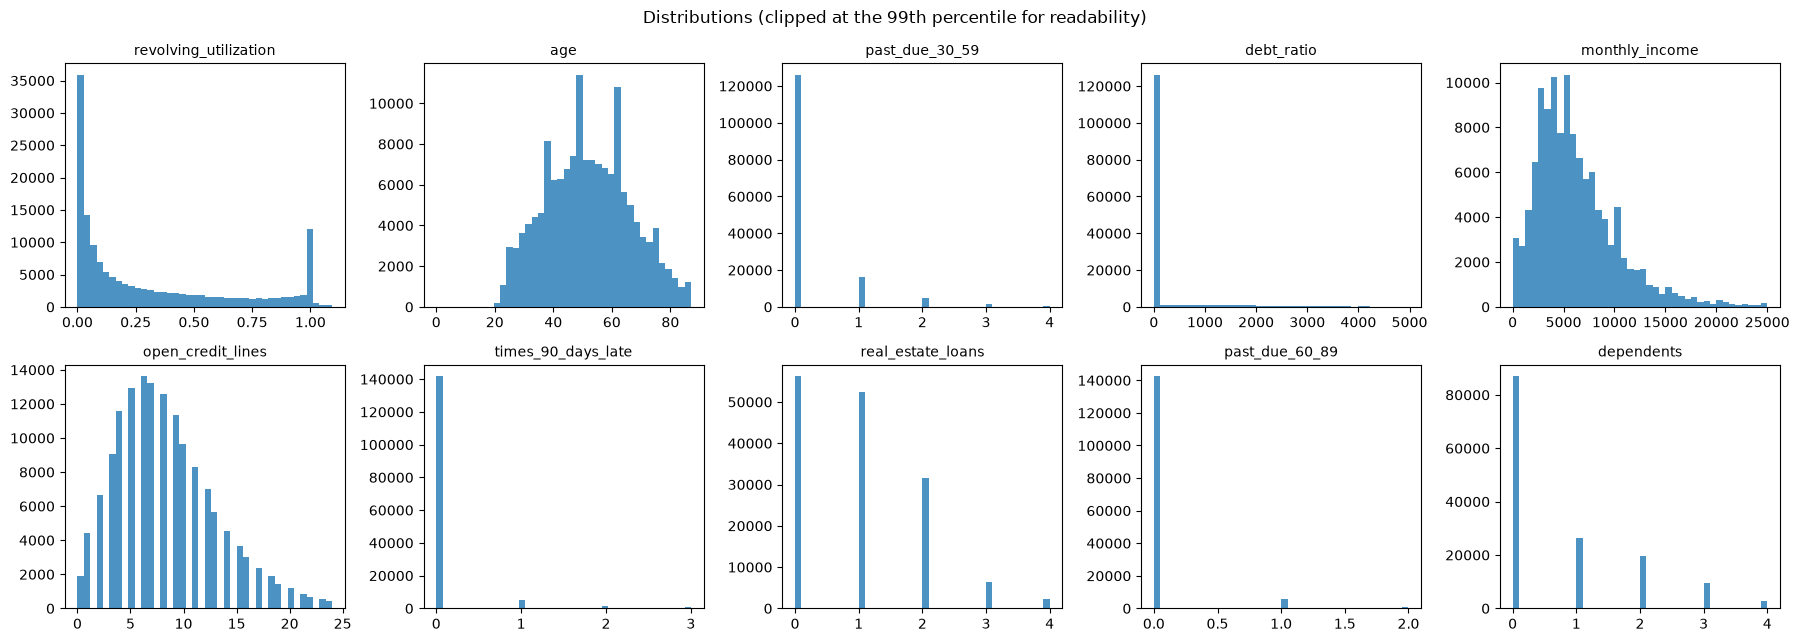

In [5]:
features = [c for c in df.columns if c != "target"]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, col in zip(axes.ravel(), features):
    x = df[col].dropna()
    upper = x.quantile(0.99)
    ax.hist(x[x <= upper], bins=40, color="tab:blue", alpha=0.8)
    ax.set_title(col, fontsize=10)
fig.suptitle("Distributions (clipped at the 99th percentile for readability)")
plt.tight_layout()
plt.show()

In [6]:
for col in ["past_due_30_59", "past_due_60_89", "times_90_days_late"]:
    vc = df[col].value_counts().sort_index()
    print(col, "| values >= 90:", vc[vc.index >= 90].to_dict())
print("revolving_utilization > 1:", f"{(df['revolving_utilization'] > 1).mean():.2%}",
      "| max:", df["revolving_utilization"].max())
print("debt_ratio > 10:", f"{(df['debt_ratio'] > 10).mean():.2%}",
      "| income missing among them:", f"{df.loc[df['debt_ratio'] > 10, 'monthly_income'].isna().mean():.2%}")
print("age == 0:", (df["age"] == 0).sum())

past_due_30_59 | values >= 90: {96: 5, 98: 264}
past_due_60_89 | values >= 90: {96: 5, 98: 264}
times_90_days_late | values >= 90: {96: 5, 98: 264}
revolving_utilization > 1: 2.21% | max: 50708.0
debt_ratio > 10: 19.25% | income missing among them: 92.71%
age == 0: 1


Data-quality findings:
* Delinquency counters contain **96 / 98** — these are reporting codes, not "98 late payments".
  → converted to NaN plus a `delinquency_code` flag (these borrowers are very risky, the flag keeps the signal).
* `revolving_utilization` should be within 0..1 but has values up to tens of thousands;
  `debt_ratio` is huge mostly where income is missing (debt divided by ~1).
  → trees are robust to this; for logistic regression we **winsorize** at the 1st/99th percentiles learned on train.
* One borrower has `age == 0` — an obvious entry error; kept (single row), the model is robust to it.
* Heavy right skew in income / ratios → tree models need no transformation; linear model gets clipping + scaling.

## 4. Default rate vs. key features

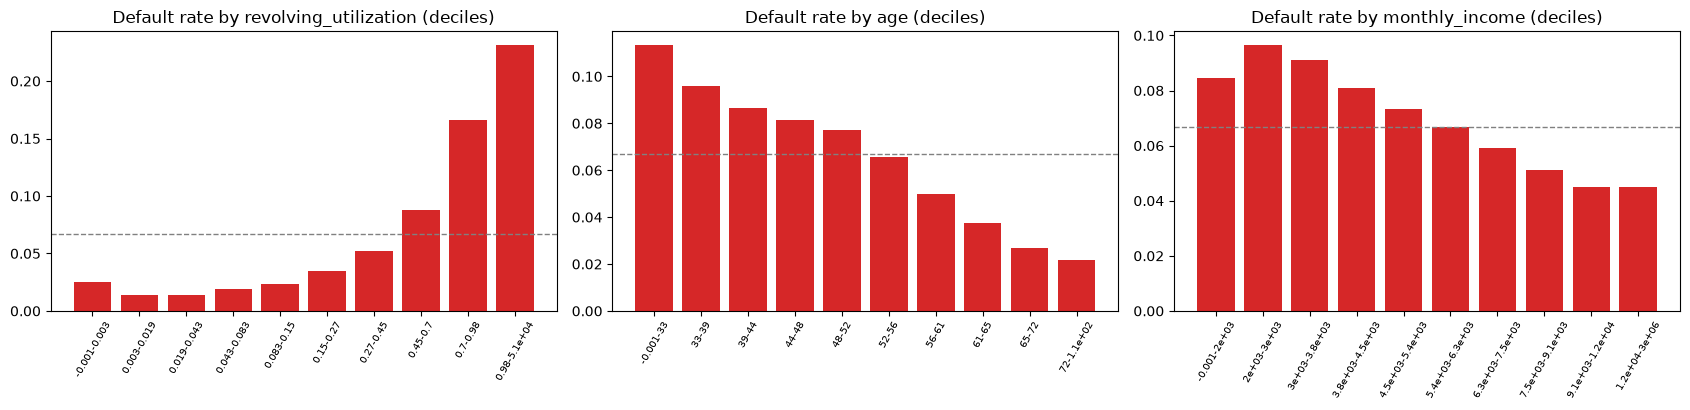

In [7]:
def rate_by_bins(col, q=10):
    bins = pd.qcut(df[col], q=q, duplicates="drop")
    return df.groupby(bins, observed=True)["target"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, ["revolving_utilization", "age", "monthly_income"]):
    r = rate_by_bins(col)
    ax.bar(range(len(r)), r["mean"], color="tab:red")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([f"{i.left:.2g}-{i.right:.2g}" for i in r.index], rotation=60, fontsize=7)
    ax.axhline(df["target"].mean(), color="gray", ls="--", lw=1)
    ax.set_title(f"Default rate by {col} (deciles)")
plt.tight_layout()
plt.show()

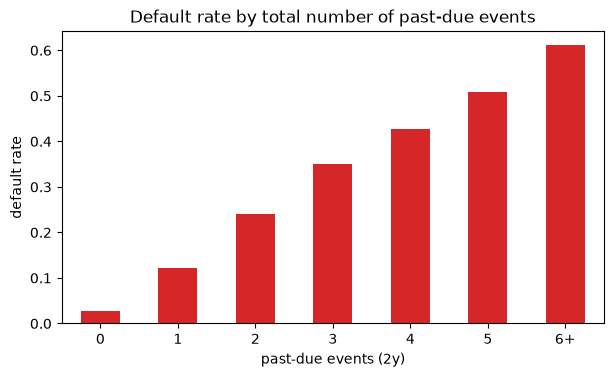

,mean,size
0,0.028,119906
1,0.122,17243
2,0.241,5942
3,0.350,2884
4,0.426,1595
5,0.509,940
6+,0.612,1490


In [8]:
total_late = df[["past_due_30_59", "past_due_60_89", "times_90_days_late"]].where(lambda x: x < 90).sum(axis=1)
grp = df.groupby(total_late.clip(upper=6))["target"].agg(["mean", "size"])
grp.index = [str(int(i)) if i < 6 else "6+" for i in grp.index]
ax = grp["mean"].plot.bar(color="tab:red", figsize=(7, 3.8))
ax.set(title="Default rate by total number of past-due events", xlabel="past-due events (2y)", ylabel="default rate")
plt.xticks(rotation=0)
plt.show()
grp

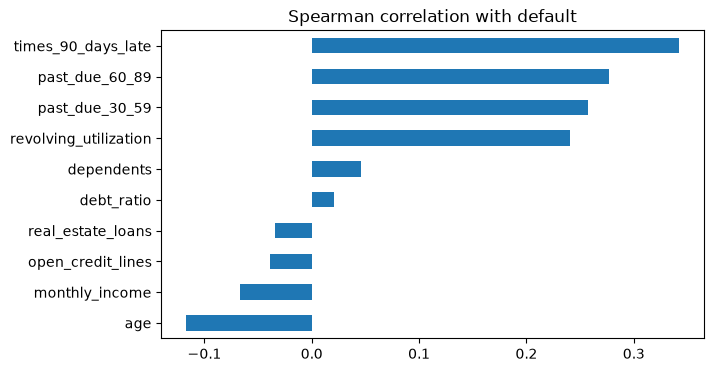

In [9]:
corr = df.corr(method="spearman")["target"].drop("target").sort_values()
corr.plot.barh(figsize=(7, 4), title="Spearman correlation with default")
plt.show()

## 5. Conclusions

1. **Imbalanced target (~6.7%)** → ROC-AUC / Gini / PR-AUC / KS as metrics, stratified CV, no resampling
   (we need calibrated PD for pricing and the cost-based cut-off).
2. **Strongest risk drivers**: past delinquencies (monotonic: each extra past-due event sharply increases risk),
   revolving utilization (default rate grows from ~1.5–2.5% in the lowest deciles to ~23% in the top decile)
   and age (11% in the youngest decile vs 2% in the oldest). Income has a weaker, non-monotonic effect
   (peaks in the 2nd decile, then decreases to ~4.5%).
3. **Data quality**: codes 96/98 in delinquency counters, utilization > 1, extreme debt ratios when income is missing.
   Fixes are row-wise (no leakage) and live in `FeatureEngineer`; learned fixes (clipping, imputation) — in the pipeline.
4. **Engineered features**: `total_past_due`, `monthly_debt = debt_ratio × income`, `income_per_person`,
   `non_real_estate_lines`, `income_missing`, `delinquency_code`.
5. Non-linear effects and interactions (utilization × delinquencies, age) → gradient boosting
   (LightGBM / CatBoost) is expected to beat logistic regression; the linear model is kept as an interpretable baseline.